In [ ]:
import Pkg; Pkg.activate(@__DIR__); Pkg.instantiate()

In [1]:
using LinearAlgebra
using SparseArrays

In [2]:
### Constants
μ_mks = 398600.44 #Earth standard gravitational parameter (km^3/sec^2)
J2_mks = 1.75553e10 #Earth J2 gravity coefficient (km^5/sec^2)
Re_mks = 6378.1 #Radius of the Earth (km)
Ωe_mks = 7.292115e-5 #Rotation rate of Earth (rad/sec)

Cd = 2.2 #Drag coefficient (unitless)
AoM_mks = (2+sqrt(2))*3e-4*1e-4/3.0; #Area-to-mass ratio (km^2/kg) assumes a 3U CubeSat with deployable panels and mass of 3 kg
AoM0_mks = 1e-4*1e-4/3.0; #Area-to-mass ratio (km^2/kg) assumes a 3U CubeSat with deployable panels and mass of 3 kg

In [3]:
#Orbital Parameters (roughly ISS)
a_mks = 6791.0 #semi-major axis (km)
inc = 51.5 #inclination (deg)
n_mks = sqrt(μ_mks/a_mks^3) #mean motion (rad/sec)
P_mks = 2*pi/n_mks; #orbital period (sec)

In [4]:
#Normalize units
a = 1.0 #distance unit is semi-major axis
P = 1.0 #time unit is orbital period
n = 2*pi
μ = (2*pi)^2 #μ_mks*(P_mks^2/a_mks^3)
J2 = J2_mks*(P_mks^2/a_mks^5)
Re = Re_mks/a_mks
Ωe = Ωe_mks*P_mks;

#a0 = a0_mks/a_mks
#H = H_mks/a_mks
#ρ0 = ρ0_mks*(a_mks^3)
AoM = AoM_mks/(a_mks^2)
AoM0 = AoM0_mks/(a_mks^2);

In [5]:
### Coordinate and unit transformations

function cartesian_to_spherical(x)
    r = sqrt(x[1:3]'*x[1:3]) #range
    ϕ = atan(x[2],x[1]) #azimuth
    θ = atan(x[3],sqrt(x[1:2]'*x[1:2])) #elevation measured up from equatorial plane
    
    return [r; ϕ; θ]
end

function spherical_to_cartesian(s)
    r = s[1] #range
    ϕ = s[2] #azimuth
    θ = s[3] #elevation measured up from equatorial plane
    
    x = r*cos(θ)*cos(ϕ)
    y = r*cos(θ)*sin(ϕ)
    z = r*sin(θ)
    
    return [x; y; z]
end

function rtn_frame(x0)
    r = x0[1:3]
    v = x0[4:6]
    n = cross(r,v)
    
    R = r/norm(r)
    N = n/norm(n)
    T = cross(N,R)
    
    return [R T N] #rotation matrix from RTN to Cartesian frame
end

function rtn_to_cartesian(x0,δr)
    r0 = x0[1:3]
    v0 = x0[4:6]
    
    R = rtn_frame(x0) #rotation from RTN to Cartesian frame
    r = R*δr + r0 #position in inertial frame
    
    return r
end

function cartesian_to_rtn(x0,r)
    r0 = x0[1:3]
    v0 = x0[4:6]
    
    R = rtn_frame(x0) #rotation from RTN to Cartesian frame
    δr = R'*(r - r0) #position in RTN frame
    
    return δr
end

function cartesian_to_ΔaθΩ(x0,x1)
    r0 = x0[1:3]
    v0 = x0[4:6]
    
    r1 = x1[1:3]
    v1 = x1[4:6]
    
    Δa = norm(r1) - norm(r0)
    
    R = rtn_frame(x0) #rotation from RTN to Cartesian frame    
    rtn1 = R'*r1
    Δθ = atan(rtn1[2]/norm(rtn1[1:2]), rtn1[1]/norm(rtn1[1:2]))
    
    h0 = cross(r0,v0)
    Ω0 = atan(h0[2]/norm(h0[1:2]), h0[1]/norm(h0[1:2]))
    
    h1 = cross(r1,v1)
    Ω1 = atan(h1[2]/norm(h1[1:2]), h1[1]/norm(h0[1:2]))
    
    ΔΩ = Ω1-Ω0
    
    return [Δa; Δθ; ΔΩ]
end

function mks_to_orbital(x)
    #change state from MKS units to orbital units
    
    return [x[1:3]/a_mks; x[4:6]*(P_mks/a_mks)]
end

function orbital_to_mks(x)
    #change state from orbital units to MKS
    
    return [x[1:3]*a_mks; x[4:6]*(a_mks/P_mks)]
end

orbital_to_mks (generic function with 1 method)

In [6]:
function density_mks(alt)
    #This fit is good from 250-500 km altitude
    #Units are km, kg
    a = 106.2
    b = -0.03243
    c = 1.988
    d = -0.01672
    ρ = a*exp(b*alt) + c*exp(d*alt)
end

function atm_density(r)
    #ρ = ρ0*exp((a0-r)/H)
    ρ = (a_mks^3)*density_mks(r*a_mks - Re_mks)
end

atm_density (generic function with 1 method)

In [7]:
#Drag perturbation at initial altitude

#Fd_mks = 0.5*Cd*density_mks(a_mks-Re_mks)*(AoM_mks)*(n_mks*a_mks)^2
#ȧ_mks = 2*(a_mks^2/μ_mks)*a_mks*n_mks*Fd_mks

#a_mid = a-5.0/a_mks #evaluate drag at average altitude of maneuver
Fd = 0.5*Cd*atm_density(a)*(AoM)*(n*a)^2
ȧ = 2*(a^2/μ)*(a)*n*Fd

6.9182039228687735e-6

In [8]:
#Continuous-Time Linear model
#state is [Δθ; Δa; ΔΩ] where these are differences between satellite 1 and satellite 2
#Can treat drag input as positive part going to sat 2 and negative part going to sat 1

k1 = (3.0/2)*sqrt(μ/a^5) #dθ̇/da (dn/da)
k2 = (21.0/4)*J2*cosd(inc)/sqrt(μ*a^9) #dΩ̇/da
k3 = ȧ #dȧ/d(Drag)

A0 = [0 -k1 0; 0 0 0; 0 -k2 0]
B0 = [0; -ȧ; 0]

3-element Vector{Float64}:
  0.0
 -6.9182039228687735e-6
  0.0

In [9]:
#Discrete-time model
h = 0.1 #time step
A = I + h*A0
B = h*B0 + 0.5*h*h*A0*B0;

In [10]:
#Initial and terminal constraints
Δx0 = zeros(3)
Δθf = 2.0*pi #one full revolution (can be any multiple of 2π)
Δaf = 0; #end at the same altitude

In [11]:
#Inequality constraints
u_min = -1
u_max = 1
Δa_min = -10/a_mks
Δa_max = 10/a_mks

0.0014725371815638344

In [12]:
#Discretized Optimal Control Problem Parameters
Nx = 3     # number of state
Nu = 1     # number of controls
Tfinal = 800.0 # final time (number of orbits)
Nt = Int(Tfinal/h)+1    # number of time steps
Nz = Nt*(Nx+Nu) #number of decision variables
thist = Array(range(0,h*(Nt-1), step=h));

In [13]:
#Useful Matrices

# decision variables are stacked z = [u1; x2; u2; x3; u3; ...; xf]
U = kron(Diagonal(I,Nt), [I zeros(Nu,Nx)]) #Matrix that picks out all u
X1 = kron(Diagonal(I,Nt), [0 1.0 0 0]) #Matrix that picks out all x1 = Δθ
X2 = kron(Diagonal(I,Nt), [0 0 1.0 0]) #Matrix that picks out all x2 = Δa
X3 = kron(Diagonal(I,Nt), [0 0 0 1.0]) #Matrix that picks out all x3 = ΔΘ
X1F = zeros(1,(Nu+Nx)*Nt); X1F[end-2] = 1.0 #Matrix that picks out x1f = Δθf
X2F = zeros(1,(Nu+Nx)*Nt); X2F[end-1] = 1.0 #Matrix that picks out x2f = Δaf

#Dynamics equality constraints C*z = d
C = sparse([[B -I zeros(Nx,(Nt-1)*(Nu+Nx))]; zeros(Nx*(Nt-1),Nu) [kron(Diagonal(I,Nt-1), [A B]) zeros((Nt-1)*Nx,Nx)] + [zeros((Nt-1)*Nx,Nx) kron(Diagonal(I,Nt-1),[zeros(Nx,Nu) Diagonal(-I,Nx)])]])
d = [-A*Δx0; zeros(Nx*(Nt-1))];

In [14]:
#Convex Formulation
using Convex

z = Variable(Nz)

problem = minimize(sum(abs(X1*z - Δθf)) + sum(abs(U*z)));
problem.constraints += [C*z == d] #dynamics constraints
problem.constraints += [X1F*z == Δθf] #final true anomaly constraint
problem.constraints += [X2F*z == Δaf] #final altitude constraint
problem.constraints += [U*z >= u_min; U*z <= u_max] #drag constraints
problem.constraints += [X2*z >= Δa_min; X2*z <= Δa_max]; #altitude constraints

In [15]:
#using ECOS
#solve!(problem, MOI.OptimizerWithAttributes(ECOS.Optimizer, "maxit" => 10000))

using MosekTools
solve!(problem, Mosek.Optimizer)

Problem
  Name                   :                 
  Objective sense        : min             
  Type                   : LO (linear optimization problem)
  Constraints            : 88014           
  Cones                  : 0               
  Scalar variables       : 48007           
  Matrix variables       : 0               
  Integer variables      : 0               

Optimizer started.
Presolve started.
Linear dependency checker started.
Linear dependency checker terminated.
Eliminator started.
Freed constraints in eliminator : 24000
Eliminator terminated.
Eliminator started.
Freed constraints in eliminator : 0
Eliminator terminated.
Eliminator - tries                  : 2                 time                   : 0.00            
Lin. dep.  - tries                  : 1                 time                   : 0.02            
Lin. dep.  - number                 : 0               
Presolve terminated. Time: 0.08    
Problem
  Name                   :                 
  Objective 

In [16]:
uhist = U*z.value;
θhist = [Δx0[1]; X1*z.value];
ahist = [Δx0[2]; X2*z.value];
Ωhist = [Δx0[3]; X3*z.value];

WebIO._IJuliaInit()

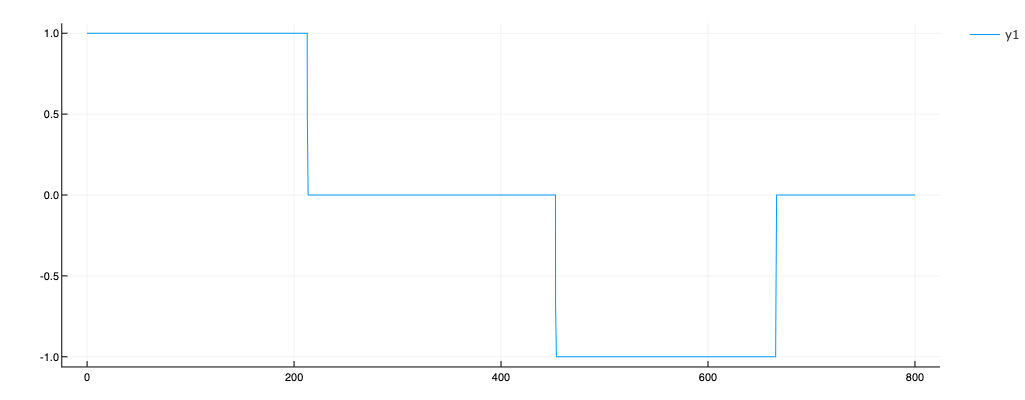

In [17]:
using Plots
plotlyjs()
plot(thist,uhist)

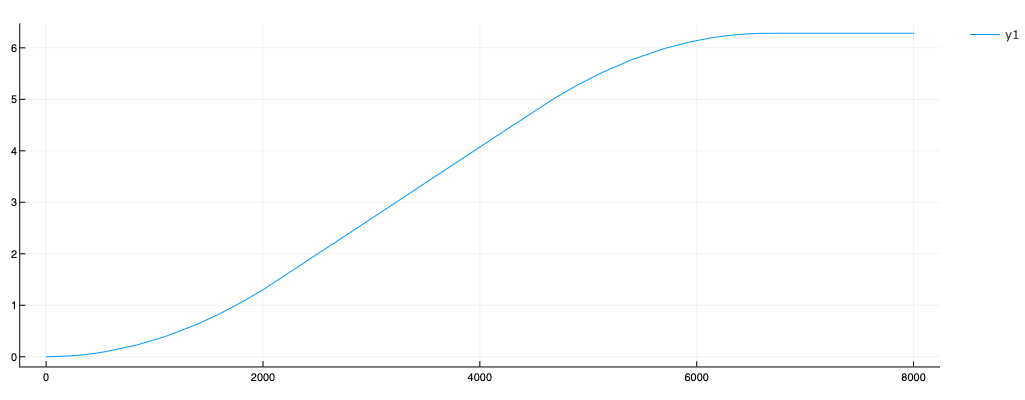

In [18]:
plot(θhist)

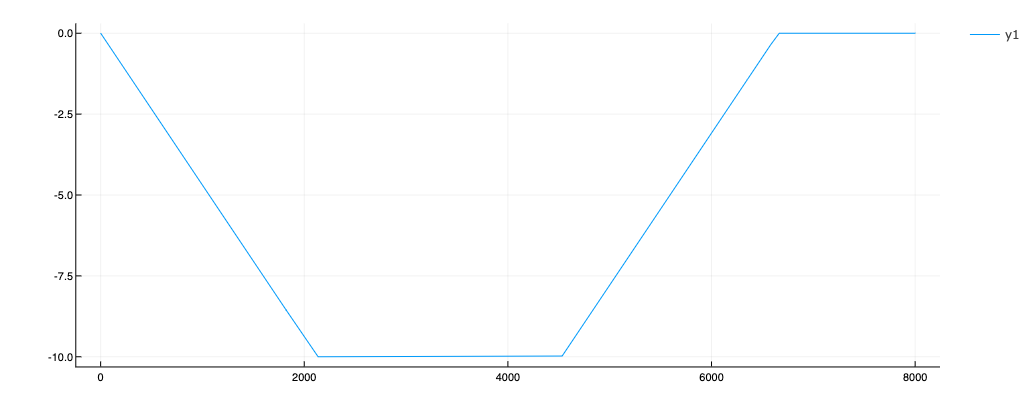

In [19]:
plot(a_mks*ahist)

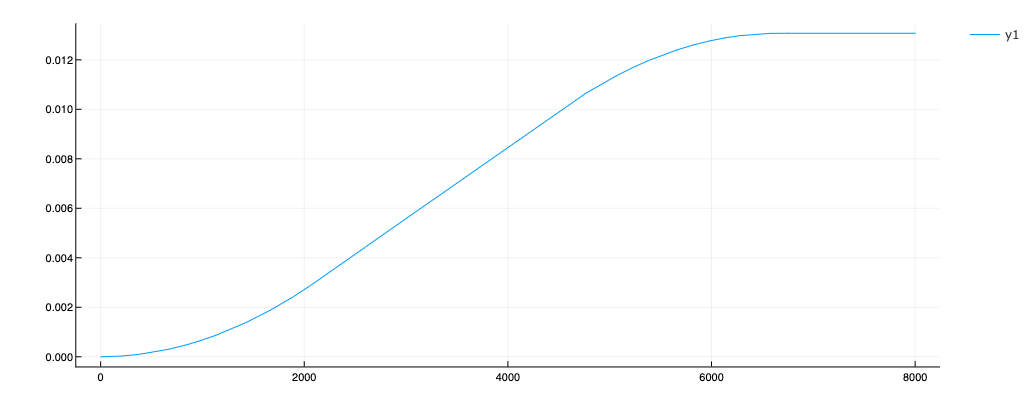

In [36]:
plot(Ωhist)

In [21]:
### Full Orbital Dynamics with J2 and Drag

using ForwardDiff

function potential(s)
    #Input is position in spherical coordinates
    r = s[1] #range
    #ϕ = s[2] #azimuth
    θ = s[3] #elevation measured up from equatorial plane
    
    #U = -(μ/r) #spherical
    U = -(μ/r) - (0.5*J2/r^3)*(3*(sin(θ)^2) - 1.0) #with J2
end

function satellite_dynamics(x,u)
    #Newton's 2nd law
    
    r = x[1:3]
    v = x[4:6]
    
    J = ForwardDiff.jacobian(cartesian_to_spherical, r)
    g = -ForwardDiff.gradient(potential, cartesian_to_spherical(r))
    
    v_rel = v - cross([0;0;Ωe],r) #Assume atmosphere co-rotates with the Earth
    ρ = atm_density(norm(r))
    Fdrag = -0.5*(u*AoM)*Cd*ρ*norm(v_rel)*v_rel
    
    v̇ = J'*g + Fdrag
    
    return [v; v̇]
end

satellite_dynamics (generic function with 1 method)

In [22]:
#Interpolation of control input trajectory from solver

using Interpolations
uinterp = LinearInterpolation(thist, uhist[:]);

function formation_dynamics!(ẋ,x,p,t)    
    x1 = x[1:6]
    x2 = x[7:12]
    
    u = uinterp(t)
    u1 = max(0, -u)
    u2 = max(0, u)
    
    ẋ1 = satellite_dynamics(x1,u1)
    ẋ2 = satellite_dynamics(x2,u2)
    
    ẋ .= [ẋ1; ẋ2]
end

formation_dynamics! (generic function with 1 method)

In [23]:
#Initial conditions in Cartesian Coordinates
r0 = [a; 0; 0]
v0 = [0; cosd(inc)*sqrt(μ/a); sind(inc)*sqrt(μ/a)]
x0 = [r0; v0];

r1 = [a; 0; 0]
v1 = [0; cosd(inc)*sqrt(μ/(a)); sind(inc)*sqrt(μ/(a))]
x1 = [r1; v1];

In [24]:
#Full Orbit Mechanics Simulation

using DifferentialEquations

tspan = (0.0, 800*P)

ref_prob = ODEProblem(formation_dynamics!,[x0; x1],tspan)
ref_soln = solve(ref_prob,Tsit5(); abstol=1e-9,reltol=1e-9);

In [25]:
#Calculate relative positions
x0_soln = zeros(6,Nt)
x1_soln = zeros(6,Nt)
Δa_soln = zeros(Nt)
Δθ_soln = zeros(Nt)
ΔΩ_soln = zeros(Nt)
for k = 1:Nt
    x0_soln[:,k] = ref_soln(thist[k])[1:6]
    x1_soln[:,k] = ref_soln(thist[k])[7:12]
    ΔaθΩ = cartesian_to_ΔaθΩ(x0_soln[:,k], x1_soln[:,k])
    Δa_soln[k] = ΔaθΩ[1]
    Δθ_soln[k] = ΔaθΩ[2]
    ΔΩ_soln[k] = ΔaθΩ[3]
end

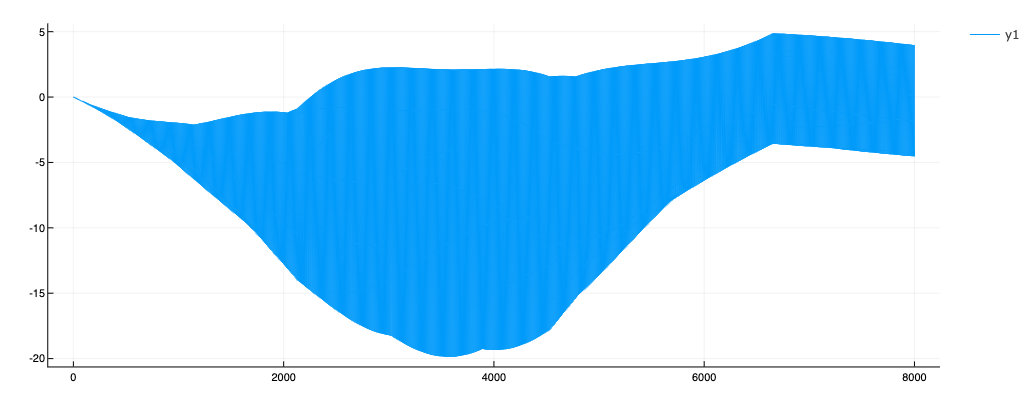

In [26]:
plot(a_mks*Δa_soln)

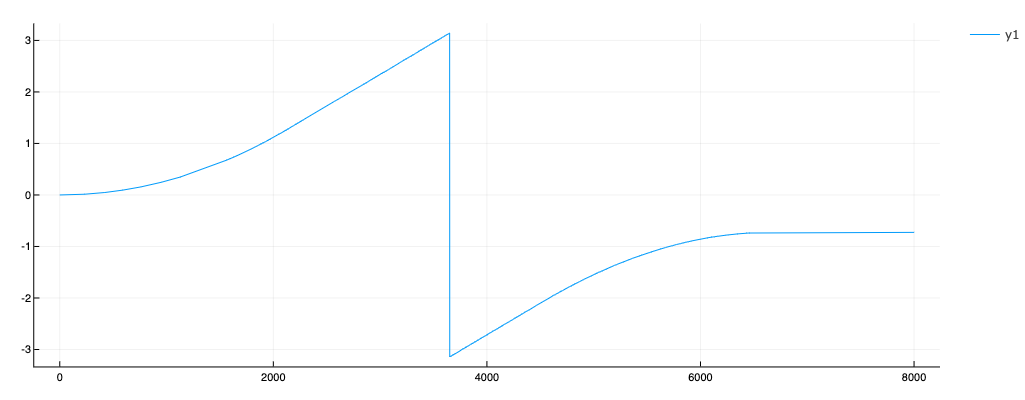

In [27]:
plot(Δθ_soln)

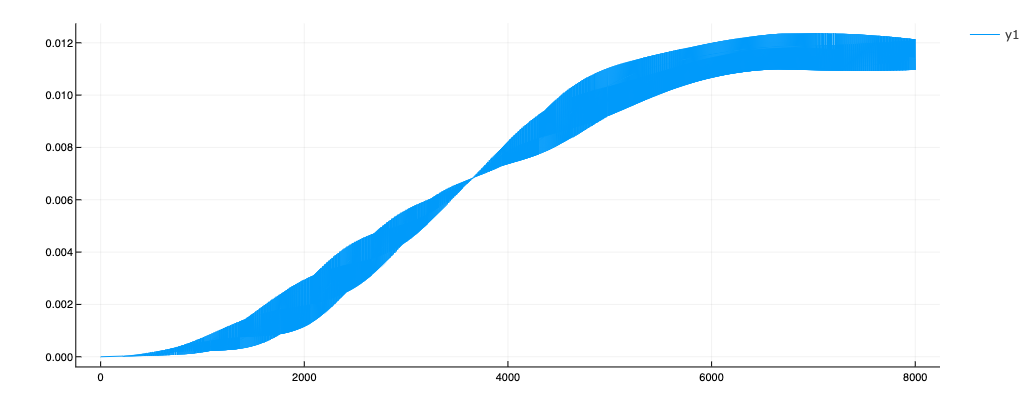

In [28]:
plot(ΔΩ_soln)

In [29]:
#Calculate altitude
Nt = 1000
tsamp = LinRange(tspan[1],tspan[2],Nt)
alt0 = zeros(Nt)
alt1 = zeros(Nt)
E0 = zeros(Nt)
E1 = zeros(Nt)
for k = 1:Nt
    alt0[k] = (norm(ref_soln(tsamp[k])[1:3])-Re)*a_mks
    alt1[k] = (norm(ref_soln(tsamp[k])[7:9])-Re)*a_mks
    E0[k] = 0.5*ref_soln(tsamp[k])[4:6]'*ref_soln(tsamp[k])[4:6] + potential(cartesian_to_spherical(ref_soln(tsamp[k])[1:3]))
    E1[k] = 0.5*ref_soln(tsamp[k])[10:12]'*ref_soln(tsamp[k])[10:12] + potential(cartesian_to_spherical(ref_soln(tsamp[k])[7:9]))
end

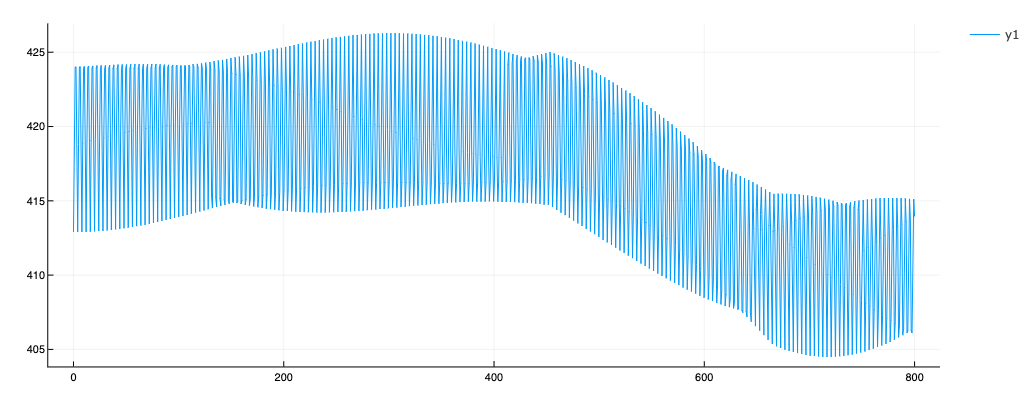

In [30]:
plot(tsamp,alt0)

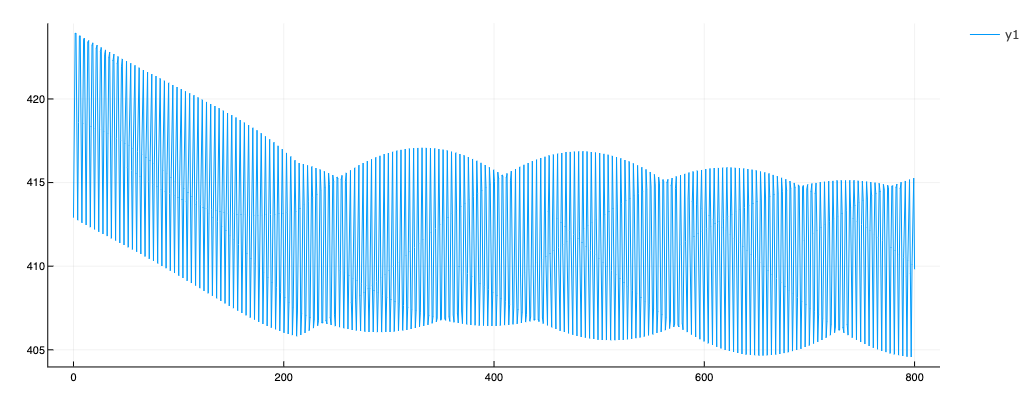

In [31]:
plot(tsamp,alt1)

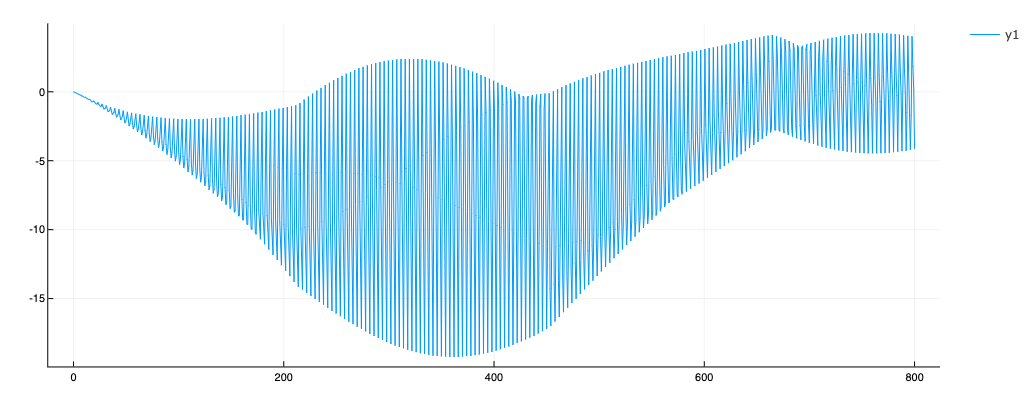

In [32]:
plot(tsamp,alt1-alt0)

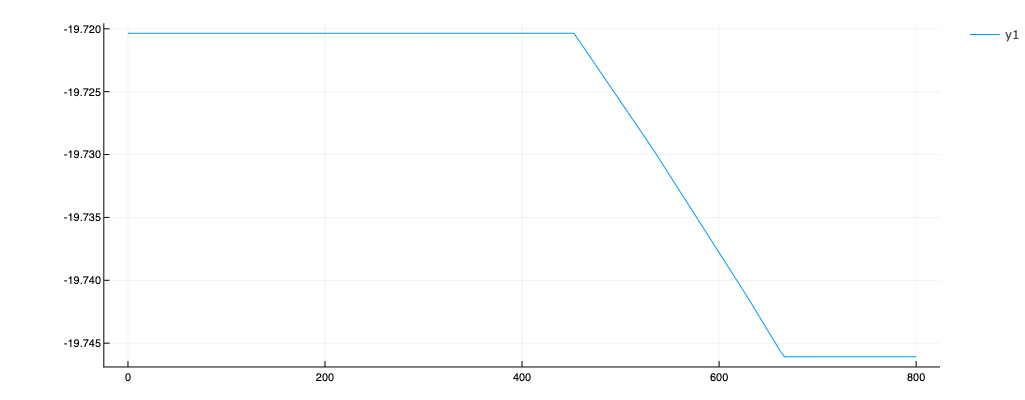

In [33]:
plot(tsamp,E0)

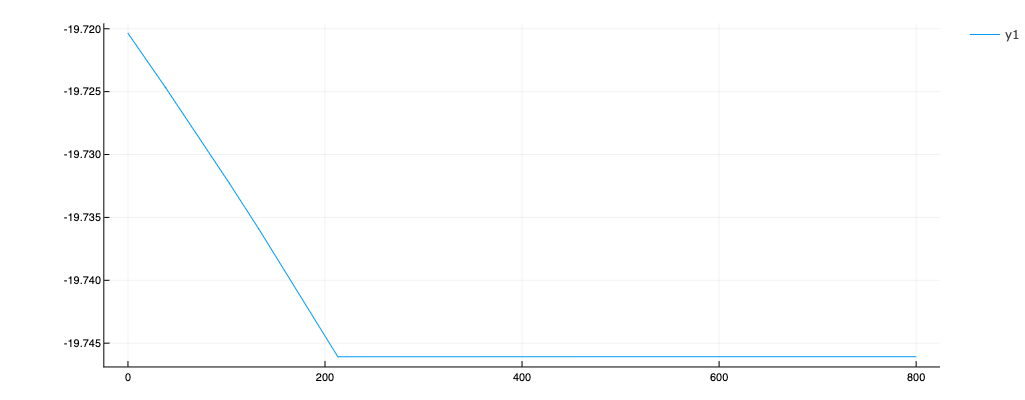

In [34]:
plot(tsamp,E1)

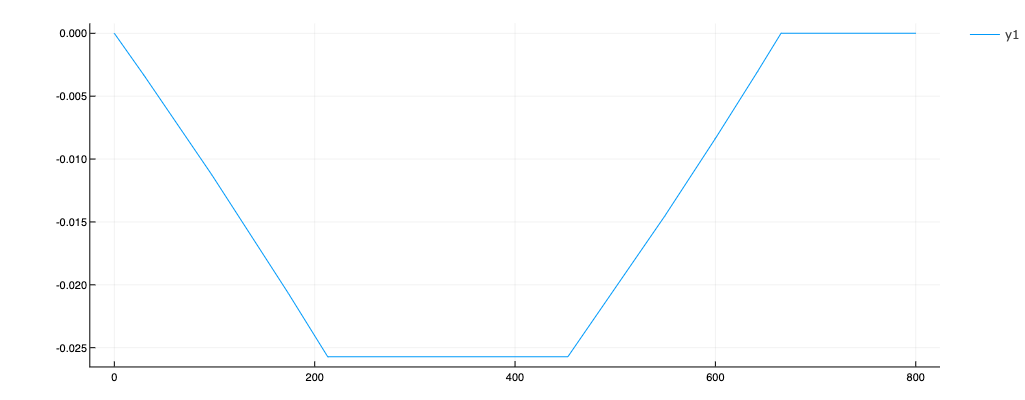

In [35]:
plot(tsamp,E1-E0)